# Hippocampus-Segmentierung mit U-Net
Datensatz: Medical Segmentation Decathlon, Task04_Hippocampus (CC-BY-SA 4.0)

## 1. Setup

In [1]:
import glob
import numpy as np
import nibabel as nib
import cv2
import matplotlib.pyplot as plt
from scipy.stats import zscore
from sklearn.model_selection import train_test_split

np.random.seed(42)

## 2. Daten laden und anschauen

In [2]:
!wget -q https://msd-for-monai.s3-us-west-2.amazonaws.com/Task04_Hippocampus.tar
!tar -xf Task04_Hippocampus.tar
!ls Task04_Hippocampus

dataset.json  imagesTr	imagesTs  labelsTr


In [3]:
bilder = sorted(glob.glob("Task04_Hippocampus/imagesTr/hippocampus*.nii.gz"))
print(len(bilder))

img = nib.load(bilder[0]).get_fdata()
maske_pfad = bilder[0].replace("imagesTr","labelsTr")
label = nib.load(maske_pfad).get_fdata()
print(img.shape, label.shape)
print(np.unique(label))

260
(35, 51, 35) (35, 51, 35)
[0. 1. 2.]


In [4]:
shapes = np.array([nib.load(bild).shape for bild in bilder])
print(shapes.min(axis=0))
print(shapes.max(axis=0))

[31 40 24]
[43 59 47]


In [5]:
img_norm = zscore(img, axis=None)
print(img_norm.mean(), img_norm.std())

1.0918303742772248e-16 1.0


## 3. Split nach Patient
Eine Datei = ein Patient. Aufgeteilt wird die Pfadliste, nicht die Schichten (kein Data Leakage).

In [6]:
train_bilder, rest_bilder = train_test_split(bilder, test_size=0.3, random_state=42)
val_bilder, test_bilder = train_test_split(rest_bilder, test_size=0.5, random_state=42)
print(len(train_bilder), len(val_bilder), len(test_bilder))

182 39 39


In [7]:
print(len(set(train_bilder) & set(val_bilder)))
print(len(set(train_bilder) & set(test_bilder)))
print(len(set(val_bilder) & set(test_bilder)))

0
0
0


## 4. Vorverarbeitung
z-Score pro Volumen, Schichten entlang Achse 0, Padding auf 64 x 64.

In [8]:
def pad_64(schicht, fuellwert):
  schicht = schicht.astype(np.float32)
  fehlt_h = 64 - schicht.shape[0]
  fehlt_b = 64 - schicht.shape[1]
  oben = fehlt_h // 2
  unten = fehlt_h - oben
  links = fehlt_b // 2
  rechts = fehlt_b - links
  return cv2.copyMakeBorder(schicht, oben, unten, links, rechts, cv2.BORDER_CONSTANT, value=fuellwert)

In [9]:
def erzeuge_schichten(pfade, fuellwert):
  X = []
  Y = []
  for bild in pfade:
    img = nib.load(bild).get_fdata()
    img_norm = zscore(img, axis=None)
    if fuellwert == "min":
      wert = float(img_norm.min())
    else:
      wert = fuellwert
    maske_pfad = bild.replace("imagesTr","labelsTr")
    label = nib.load(maske_pfad).get_fdata()
    for i in range(img_norm.shape[0]):
      X.append(pad_64(img_norm[i], wert))
      Y.append(pad_64(label[i], 0))
  return np.array(X), np.array(Y)

In [10]:
X_train, Y_train = erzeuge_schichten(train_bilder, 0)
print(X_train.shape, Y_train.shape)

(6424, 64, 64) (6424, 64, 64)


In [11]:
leer = (Y_train.max(axis=(1,2)) == 0).sum()
print(leer, "von", len(Y_train), "Schichten sind leer")

2419 von 6424 Schichten sind leer


## 5. Augmentation (nur Training)

In [12]:
def rotiere(bild, maske):
  winkel = np.random.uniform(-10,10)
  drehmatrix = cv2.getRotationMatrix2D((32, 32), winkel, 1.0)
  bild = cv2.warpAffine(bild, drehmatrix, (64, 64), flags=cv2.INTER_LINEAR)
  maske = cv2.warpAffine(maske, drehmatrix, (64, 64), flags=cv2.INTER_NEAREST)
  return bild, maske

In [13]:
def helligkeit_kontrast(bild):
  kontrast = np.random.uniform(0.9, 1.1)
  helligkeit = np.random.uniform(-0.1, 0.1)
  bild = kontrast * bild + helligkeit
  return bild

In [14]:
def augmentiere(bild, maske):
  if np.random.rand() < 0.5:
    bild = helligkeit_kontrast(bild)
  if np.random.rand() < 0.5:
    bild, maske = rotiere(bild, maske)
  return bild, maske

### Checks

[0. 1. 2.]


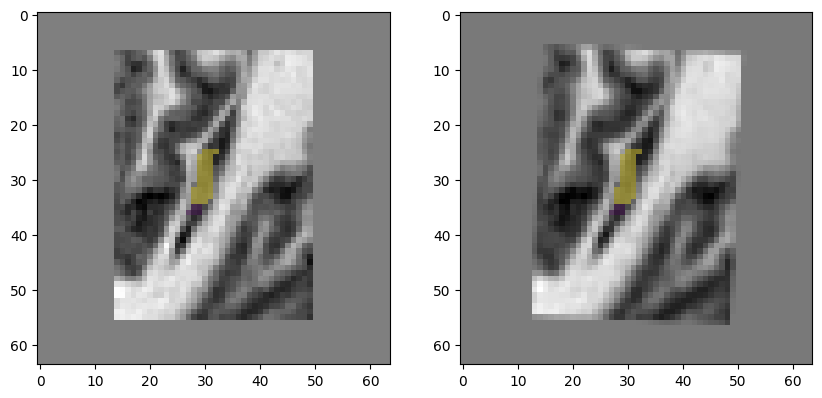

In [15]:
nicht_leer = np.where(Y_train.max(axis=(1,2)) > 0)[0]
idx = nicht_leer[0]
bild, maske = X_train[idx], Y_train[idx]
rotbild, rotmaske = rotiere(bild, maske)
print(np.unique(rotmaske))

fig, ax = plt.subplots(1,2, figsize=(10,5))
ax[0].imshow(bild, cmap="gray")
ax[0].imshow(np.ma.masked_where(maske == 0, maske), alpha=0.4)
ax[1].imshow(rotbild, cmap="gray")
ax[1].imshow(np.ma.masked_where(rotmaske == 0, rotmaske), alpha=0.4)
plt.show()

In [16]:
newbild = helligkeit_kontrast(bild)
print(bild.mean(), bild.std())
print(newbild.mean(), newbild.std())

0.026908904 0.6731493
0.075733334 0.73382884


In [17]:
for i in range(0,5):
  bild_aug, maske_aug = augmentiere(X_train[idx], Y_train[idx])
  print(bild_aug.mean())

0.026902271
0.049102582
0.09262513
0.030614441
0.02689507


## 6. Dataset und DataLoader

In [18]:
import torch
from torch.utils.data import Dataset, DataLoader
class HippocampusDataset(Dataset):
  def __init__(self, X, Y, augmented = False):
    self.X = X
    self.Y = Y
    self.augmented = augmented

  def __len__(self):
    return len(self.X)

  def __getitem__(self, idx):
    bild = self.X[idx]
    maske = self.Y[idx]
    if self.augmented:
      bild, maske = augmentiere(bild,maske)
    bild = torch.from_numpy(bild).float().unsqueeze(0)
    maske = torch.from_numpy(maske).long()
    return bild, maske




In [19]:
ds = HippocampusDataset(X_train, Y_train, augmented=True)
b, m = ds[idx]
print(b.shape, b.dtype)
print(m.shape, m.dtype)

torch.Size([1, 64, 64]) torch.float32
torch.Size([64, 64]) torch.int64


In [20]:
train_dl = DataLoader(HippocampusDataset(X_train, Y_train, augmented=True), batch_size=32, shuffle=True)
b, m = next(iter(train_dl))
print(b.shape, m.shape)

torch.Size([32, 1, 64, 64]) torch.Size([32, 64, 64])


## 7. U-Net
Encoder (64 → 32 → 16), Bottleneck, Decoder (16 → 32 → 64) mit Skip-Verbindungen. Ausgabe: 3 Karten pro Pixel (Hintergrund, anterior, posterior).

In [21]:
import torch.nn as nn

class ConvBlock(nn.Module):
  def __init__(self,ein,aus):
    super().__init__()
    self.block = nn.Sequential(
        nn.Conv2d(ein,aus,3,padding=1),
        nn.BatchNorm2d(aus),
        nn.ReLU(),
        nn.Conv2d(aus,aus,3,padding=1),
        nn.BatchNorm2d(aus),
        nn.ReLU()
    )
  def forward(self,x):
    return self.block(x)

In [22]:
block = ConvBlock(1, 16)
print(block(b).shape)

torch.Size([32, 16, 64, 64])


In [23]:
class UNet(nn.Module):
  def __init__(self):
    super().__init__()
    self.enc1 = ConvBlock(1,16)
    self.enc2 = ConvBlock(16,32)
    self.bottleneck = ConvBlock(32,64)
    self.pool = nn.MaxPool2d(2)
    self.up2 = nn.ConvTranspose2d(64,32,2,2)
    self.dec2 = ConvBlock(64,32)
    self.up1 = nn.ConvTranspose2d(32,16,2,2)
    self.dec1 = ConvBlock(32,16)
    self.out = nn.Conv2d(16,3,1)


  def forward(self,x):
    e1 = self.enc1(x)
    x1 = self.pool(e1)
    e2 = self.enc2(x1)
    x2 = self.pool(e2)
    bn = self.bottleneck(x2)
    d2 = self.up2(bn)
    d2 = torch.cat((d2,e2),dim=1)
    d2 = self.dec2(d2)
    d1 = self.up1(d2)
    d1 = torch.cat((d1,e1),dim=1)
    d1 = self.dec1(d1)
    return self.out(d1)

In [24]:
model = UNet()
print(model(b).shape)

torch.Size([32, 3, 64, 64])


## 8. Training und Validierung

In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

loss_fn = nn.CrossEntropyLoss()
print(sum(p.numel() for p in UNet().parameters()))

cuda
117427


In [26]:
def train_epoch(model, loader, optimizer):
  model.train()
  gesamt_loss = 0
  for bild, maske in loader:
    bild = bild.to(device)
    maske = maske.to(device)
    ausgabe = model(bild)
    loss = loss_fn(ausgabe, maske)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    gesamt_loss += loss.item()
  return gesamt_loss / len(loader)

Dice wird pro Klasse über alle Pixel des jeweiligen Sets berechnet (nicht pro Patient gemittelt).

In [27]:
def evaluate(model,loader):
  model.eval()
  gesamt_loss = 0
  schnitt = [0,0]
  summe = [0,0]
  with torch.no_grad():
    for bild, maske in loader:
      bild = bild.to(device)
      maske = maske.to(device)
      ausgabe = model(bild)
      pred = ausgabe.argmax(dim=1)
      for k in [1,2]:
        p = (pred == k)
        t = (maske == k)
        schnitt[k-1] += (p & t).sum().item()
        summe[k-1] += t.sum().item() + p.sum().item()
      gesamt_loss += loss_fn(ausgabe,maske).item()
  dice1 = 2*schnitt[0]/summe[0]
  dice2 = 2*schnitt[1]/summe[1]
  return gesamt_loss / len(loader), dice1, dice2

In [28]:
def experiment(fuellwert, epochen=10):
  torch.manual_seed(42)
  np.random.seed(42)

  X_tr, Y_tr = erzeuge_schichten(train_bilder, fuellwert)
  X_va, Y_va = erzeuge_schichten(val_bilder, fuellwert)
  train_dl = DataLoader(HippocampusDataset(X_tr, Y_tr, augmented=True), batch_size=32, shuffle=True)
  val_dl = DataLoader(HippocampusDataset(X_va, Y_va), batch_size=32, shuffle=False)

  model = UNet().to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

  verlauf = []
  best_dice = 0
  for epoch in range(epochen):
    train_loss = train_epoch(model, train_dl, optimizer)
    val_loss, dice1, dice2 = evaluate(model, val_dl)
    mean_dice = (dice1 + dice2) / 2
    verlauf.append((train_loss, val_loss, dice1, dice2))
    print(epoch+1, round(train_loss,3), round(val_loss,3), round(dice1,3), round(dice2,3))
    if mean_dice > best_dice:
      best_dice = mean_dice
      torch.save(model.state_dict(), f"best_model_{fuellwert}.pt")
  return verlauf

## 9. Ablation: Füllwert beim Padding
Beide Varianten von vorn trainiert, gleicher Seed, 10 Epochen. Verglichen wird nur auf dem **Validierungsset**.

In [29]:
verlauf_0 = experiment(0)

1 0.414 0.103 0.799 0.802
2 0.061 0.037 0.83 0.833
3 0.03 0.024 0.864 0.843
4 0.022 0.019 0.866 0.848
5 0.018 0.016 0.875 0.85
6 0.016 0.015 0.873 0.858
7 0.015 0.014 0.878 0.858
8 0.014 0.014 0.877 0.859
9 0.013 0.014 0.88 0.854
10 0.013 0.014 0.876 0.858


In [30]:
verlauf_min = experiment("min")

1 0.413 0.101 0.781 0.802
2 0.062 0.037 0.84 0.836
3 0.03 0.023 0.862 0.843
4 0.022 0.018 0.867 0.844
5 0.018 0.016 0.876 0.856
6 0.016 0.015 0.869 0.857
7 0.015 0.014 0.868 0.855
8 0.014 0.014 0.88 0.861
9 0.014 0.013 0.881 0.856
10 0.013 0.013 0.876 0.863


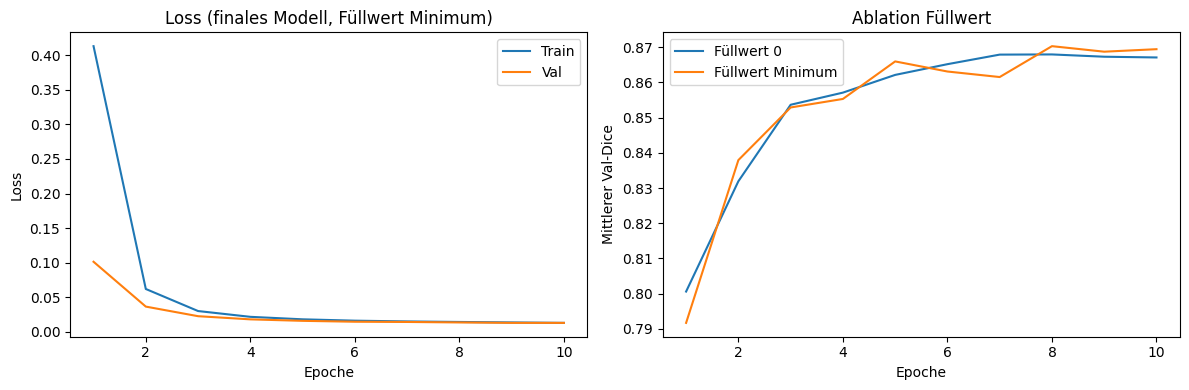

In [31]:
epochen = range(1, len(verlauf_min) + 1)
dice_0 = [(v[2] + v[3]) / 2 for v in verlauf_0]
dice_min = [(v[2] + v[3]) / 2 for v in verlauf_min]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochen, [v[0] for v in verlauf_min], label="Train")
ax[0].plot(epochen, [v[1] for v in verlauf_min], label="Val")
ax[0].set_xlabel("Epoche")
ax[0].set_ylabel("Loss")
ax[0].set_title("Loss (finales Modell, Füllwert Minimum)")
ax[0].legend()

ax[1].plot(epochen, dice_0, label="Füllwert 0")
ax[1].plot(epochen, dice_min, label="Füllwert Minimum")
ax[1].set_xlabel("Epoche")
ax[1].set_ylabel("Mittlerer Val-Dice")
ax[1].set_title("Ablation Füllwert")
ax[1].legend()

plt.tight_layout()
plt.savefig("lernkurve.png", dpi=150)
plt.show()

**Ergebnis (bester mittlerer Val-Dice):** Füllwert 0: 0.869, Füllwert Minimum: 0.873.
Der Unterschied liegt im Bereich der Schwankung zwischen Epochen, der Füllwert macht hier praktisch keinen Unterschied.
**Festlegung vor dem Test:** finales Modell = Füllwert Minimum (`best_model_min.pt`).

## 10. Test (einmalig)
Das Testset wurde nur ein einziges Mal benutzt, nachdem das finale Modell festgelegt war. Danach wurde nichts mehr verändert.

In [32]:
X_te, Y_te = erzeuge_schichten(test_bilder, "min")
test_dl = DataLoader(HippocampusDataset(X_te, Y_te), batch_size=32, shuffle=False)

model = UNet().to(device)
model.load_state_dict(torch.load("best_model_min.pt"))

test_loss, test_dice1, test_dice2 = evaluate(model, test_dl)
print(round(test_loss,3), round(test_dice1,3), round(test_dice2,3))
print("Mittel:", round((test_dice1 + test_dice2) / 2, 3))

0.015 0.874 0.854
Mittel: 0.864


## 11. Ergebnisbilder (Testset)

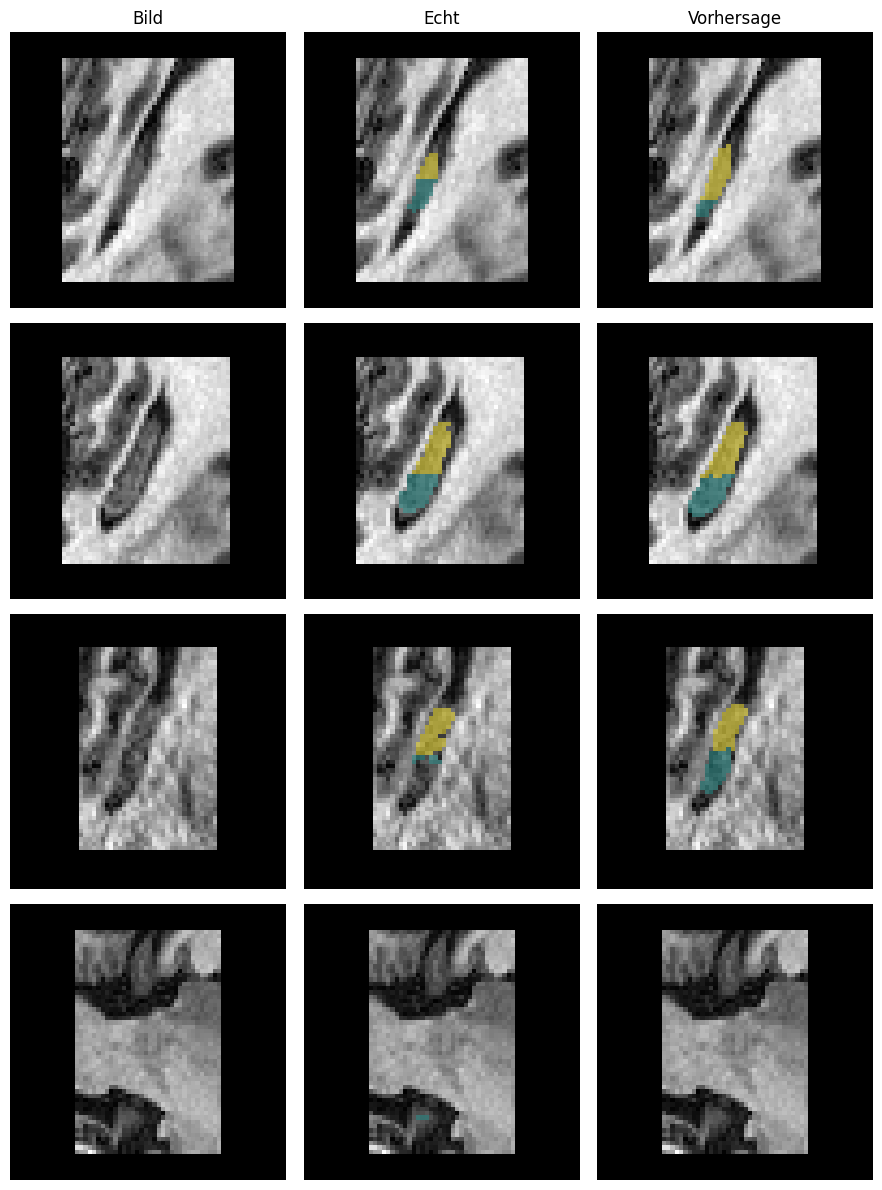

In [33]:
nicht_leer_te = np.where(Y_te.max(axis=(1,2)) > 0)[0]
beispiele = nicht_leer_te[::200][:4]

model.eval()
fig, ax = plt.subplots(4, 3, figsize=(9, 12))
for r, i in enumerate(beispiele):
  bild = X_te[i]
  echt = Y_te[i]
  eingabe = torch.from_numpy(bild).float().unsqueeze(0).unsqueeze(0).to(device)
  with torch.no_grad():
    pred = model(eingabe).argmax(dim=1)[0].cpu().numpy()

  ax[r,0].imshow(bild, cmap="gray")
  ax[r,1].imshow(bild, cmap="gray")
  ax[r,1].imshow(np.ma.masked_where(echt == 0, echt), alpha=0.5, vmin=0, vmax=2)
  ax[r,2].imshow(bild, cmap="gray")
  ax[r,2].imshow(np.ma.masked_where(pred == 0, pred), alpha=0.5, vmin=0, vmax=2)
  for c in range(3):
    ax[r,c].axis("off")

ax[0,0].set_title("Bild")
ax[0,1].set_title("Echt")
ax[0,2].set_title("Vorhersage")
plt.tight_layout()
plt.savefig("beispiele.png", dpi=150)
plt.show()